In [1]:
from config import *

from Image_charge_3d import *

import scipy.integrate

In [24]:
class potential_due_sheet: 

    def __init__(self, d, charge_density, ep_qw = 11.7, ep_sige= 11.7, ep_ox=8, t_sige=10, t_ox=15):

        self.d = d   ## charge sheet is placed at a distance d 
        self.cd = charge_density 
        self.ep_qw = ep_qw
        self.ep_sige = ep_sige
        self.ep_ox= ep_ox
        self.t_sige = t_sige
        self.t_ox = t_ox

    def image_charge(self,  xp, yp):

        img_charge = Image_charge_calculator(q_ct=1, z_ct=self.d, y_ct = yp, x_ct= xp, ep_qw = self.ep_qw, ep_sige= self.ep_sige, ep_ox=self.ep_ox, t_sige=self.t_sige, t_ox=self.t_ox, r=1e-3).calc_image_charges()

        return img_charge


    def greens_function(self, x, y, z, xp, yp):

        img_charge = Image_charge_calculator(q_ct=1, z_ct=self.d, y_ct = yp, x_ct= xp, ep_qw = self.ep_qw, ep_sige= self.ep_sige, ep_ox=self.ep_ox, t_sige=self.t_sige, t_ox=self.t_ox, r=1e-3).calc_image_charges()

        Gfn = 1/math.sqrt((x - xp)**2+(y - yp)**2+(z-self.d)**2)

        if z <= self.t_ox :

        #print('a')

            for ic in img_charge[2]:  
                ### q3s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

            for ic in img_charge[1]:
                ### q4s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)
        
        elif z <= self.t_sige and z> self.t_ox :

            for ic in img_charge[3]:  
                ### q2s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

            for ic in img_charge[4]:
                ### q1s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)

        else :

            for ic in img_charge[0]:
                ### q5s

                Gfn = Gfn + ic[0]/math.sqrt((x- xp)**2+(y- yp)**2+(z-ic[1])**2)
        
        return Gfn 


    def integrate_greens_function(self, x, y, z, xp_min, xp_max, yp_min, yp_max):

        result, error = scipy.integrate.dblquad(
            lambda xp, yp: self.greens_function(x, y, z, xp, yp),
            yp_min, yp_max,  # Integration limits for yp (outer integral)
            lambda yp: xp_min, lambda yp: xp_max  # Integration limits for xp (inner integral)
        )

        Area = (xp_max-xp_min)*(yp_max-yp_min)

        if z <= self.t_ox :

            result = 1/self.ep_ox*result

        elif z<= self.t_sige and z>self.t_ox:

            result = 1/self.ep_sige*result

        else:

            result = 1/self.ep_qw*result


        return result, error
    
    def integrate_gfn_simps(self, x, y, z, xp_min, xp_max, yp_min, yp_max, num_points):

        xp_vals = np.linspace(xp_min, xp_max, num_points)
        yp_vals = np.linspace(yp_min, yp_max, num_points)
        xp_grid, yp_grid = np.meshgrid(xp_vals, yp_vals)

        greens_values = np.vectorize(self.greens_function)(x, y, z, xp_grid, yp_grid)
        return scipy.integrate.simps(scipy.integrate.simps(greens_values, yp_vals), xp_vals)
    
    def integrate_gfn_trapz(self, x, y, z, xp_min, xp_max, yp_min, yp_max, num_points):

        xp_vals = np.linspace(xp_min, xp_max, num_points)
        yp_vals = np.linspace(yp_min, yp_max, num_points)
        xp_grid, yp_grid = np.meshgrid(xp_vals, yp_vals)

        greens_values = np.vectorize(self.greens_function)(x, y, z, xp_grid, yp_grid)
        return np.trapz(np.trapz(greens_values, yp_vals), xp_vals)


In [55]:

D = 10
X = 0 
Y = 0
Z = 5 

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V)

1.9724769748830336e+18


In [18]:

D = 10
X = 0 
Y = 0
Z = 4 

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V)

7062.968674037105


In [19]:

D = 10
X = 0 
Y = 0
Z = 0 

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V)

6988.412944100988


In [21]:

D = 10
X = 0 
Y = 0
Z = 100

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V)

6675.618476773396


In [46]:
D = 10
X = 7 
Y = 9
Z = 100

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

AREA= (XP_MAX-XP_MIN)*(YP_MAX-YP_MIN)

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V/AREA)

0.0016688587886168474


In [47]:
D = 10
X = 7 
Y = 20
Z = 100

SIG = 1

XP_MIN= -10000
XP_MAX = 10000
YP_MIN = -10000
YP_MAX = 10000


AREA= (XP_MAX-XP_MIN)*(YP_MAX-YP_MIN)

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V/AREA)

0.00017532171179905875


In [48]:
D = 10
X = 30 
Y = 20
Z = 100

SIG = 1

XP_MIN= -10000
XP_MAX = 10000
YP_MIN = -10000
YP_MAX = 10000


AREA= (XP_MAX-XP_MIN)*(YP_MAX-YP_MIN)

Mod = potential_due_sheet(D, SIG)

V = Mod.integrate_greens_function(X, Y, Z, XP_MIN, XP_MAX, YP_MIN, YP_MAX)

print(V/AREA)

0.0001753214109330198


In [36]:
Z = np.linspace(0, 100, 23)
Z

array([  0.        ,   4.54545455,   9.09090909,  13.63636364,
        18.18181818,  22.72727273,  27.27272727,  31.81818182,
        36.36363636,  40.90909091,  45.45454545,  50.        ,
        54.54545455,  59.09090909,  63.63636364,  68.18181818,
        72.72727273,  77.27272727,  81.81818182,  86.36363636,
        90.90909091,  95.45454545, 100.        ])

[3.00000000e-04 1.11568462e+00 2.23106923e+00 3.34645385e+00
 4.46183846e+00 5.57722308e+00 6.69260769e+00 7.80799231e+00
 8.92337692e+00 1.00387615e+01 1.11541462e+01 1.22695308e+01
 1.33849154e+01 1.45003000e+01 1.56156846e+01 1.67310692e+01
 1.78464538e+01 1.89618385e+01 2.00772231e+01 2.11926077e+01
 2.23079923e+01 2.34233769e+01 2.45387615e+01 2.56541462e+01
 2.67695308e+01 2.78849154e+01 2.90003000e+01]
0
3
6
9
12
15
18
21
24


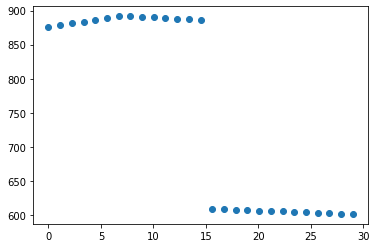

In [14]:

D = 7
X = 0
Y = 1

epsilon = 3e-4  # A tiny shift

Z = np.linspace(0, 29, 27) + epsilon

print(Z)

SIG = 1

XP_MIN= -1000
XP_MAX = 1000
YP_MIN = -1000
YP_MAX = 1000

Mod = potential_due_sheet(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i], err[i] = Mod.integrate_greens_function(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)



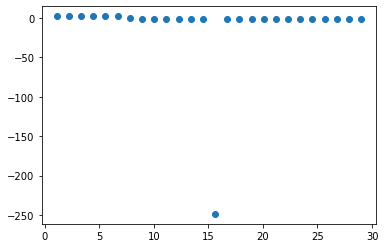

In [15]:
E = np.diff(V) / np.diff(Z)

plt.scatter(Z[1:], E)

In [20]:
print(np.round(E))

[   2.    2.    2.    2.    2.    2.    0.   -1.   -1.   -1.   -1.   -1.
   -1. -249.   -1.   -1.   -1.   -1.   -1.   -1.   -1.   -1.   -1.   -1.
   -1.   -1.]


In [22]:
Q = Mod.image_charge(0,0)
print(Q[0]) ##q5
print(Q[1]) ##q4
print(Q[2]) ##q3
print(Q[3]) ##q2
print(Q[4]) ##q1


[(0.001478058498477397, -113, 10, 'q5k'), (0.007869662816217492, -83, 8, 'q5k'), (0.041900637156617467, -53, 6, 'q5k'), (0.22309258161766599, -23, 4, 'q5k'), (1.1878172588832487, 7, 2, 'q5k'), (-0.001478058498477397, -127, 10, 'q5k'), (-0.007869662816217492, -97, 8, 'q5k'), (-0.041900637156617467, -67, 6, 'q5k'), (-0.22309258161766599, -37, 4, 'q5k'), (-1.1878172588832487, -7, 2, 'q5k')]
[(1, 7, 0, 'q4j'), (-1, -7, 0, 'q4j'), (0.1878172588832487, -23, 2, 'q4j'), (0.03527532273441727, -53, 4, 'q4j'), (0.006625314422200197, -83, 6, 'q4j'), (0.0012443483940172957, -113, 8, 'q4j'), (-0.1878172588832487, -37, 2, 'q4j'), (-0.03527532273441727, -67, 4, 'q4j'), (-0.006625314422200197, -97, 6, 'q4j'), (-0.0012443483940172957, -127, 8, 'q4j')]
[(-0.1878172588832487, 23, 1, 'q3j'), (-0.03527532273441727, 53, 3, 'q3j'), (-0.006625314422200197, 83, 5, 'q3j'), (-0.0012443483940172957, 113, 7, 'q3j'), (-0.0002337101044601012, 143, 9, 'q3j'), (0.1878172588832487, 37, 1, 'q3j'), (0.03527532273441727, 6

In [25]:
D = 7
X = 0
Y = 1

epsilon = 3e-4  # A tiny shift

Z = np.linspace(0, 29, 27) + epsilon

print(Z)

SIG = 1

XP_MIN= -100
XP_MAX = 100
YP_MIN = -100
YP_MAX = 100

Mod = potential_due_sheet(D, SIG, t_ox=15, t_sige=10)
V = np.empty((Z.shape[0]))
err =  np.empty((Z.shape[0]))

for i in range(Z.shape[0]):

    V[i] = Mod.integrate_gfn_simps(X, Y, Z[i], XP_MIN, XP_MAX, YP_MIN, YP_MAX,1000)

    if i%3 == 0:

        print(i)

plt.scatter(Z, V)

[3.00000000e-04 1.11568462e+00 2.23106923e+00 3.34645385e+00
 4.46183846e+00 5.57722308e+00 6.69260769e+00 7.80799231e+00
 8.92337692e+00 1.00387615e+01 1.11541462e+01 1.22695308e+01
 1.33849154e+01 1.45003000e+01 1.56156846e+01 1.67310692e+01
 1.78464538e+01 1.89618385e+01 2.00772231e+01 2.11926077e+01
 2.23079923e+01 2.34233769e+01 2.45387615e+01 2.56541462e+01
 2.67695308e+01 2.78849154e+01 2.90003000e+01]
0
3
6
9
12


KeyboardInterrupt: 